# Ratio Metrics, the Delta Method, and Clustered Data

**What you'll learn**

- Why CTR, revenue per session, and items per order are *ratios of sums* whose
  denominator is not the randomization unit — and why treating sessions/impressions as
  i.i.d. observations produces a false-positive rate of ~30% instead of 5% in A/A tests
  on a realistically heterogeneous user population.
- The design effect $1 + (\tilde m - 1)\rho$ with the *size-weighted* mean cluster size
  $\tilde m$: how a tiny intra-user correlation (ICC ≈ 0.06) plus heavy-tailed usage
  turns into a variance inflation of ~3.6×, and how to predict the naive test's
  false-positive rate from it analytically.
- The delta method for a ratio of means: derivation, a 10-line implementation, and a
  ground-truth validation showing its SE matches the true sampling SD within ~1% while
  the naive SE is off by ~1.9×. Plus the linearization view that turns any ratio metric
  back into a plain user-level mean.
- Ratio-of-averages vs average-of-ratios: two different estimands both called "CTR"
  (5.5% vs 9.1% on the *same data* here), when each is the right business metric, and a
  head-to-head table of user-level averaging, cluster bootstrap, delta method, and
  cluster-robust regression.
- Why percentile metrics (p90 latency) need special handling: i.i.d. order-statistic CIs
  collapse to ~68% coverage under user clustering; the user-level bootstrap fixes it.

**Why it matters in interviews**

- "We randomize by user but the metric is CTR — what breaks and how do you fix it?" is
  arguably *the* screening question for senior experimentation roles. The expected
  keywords: analysis unit ≠ randomization unit, delta method, cluster bootstrap,
  cluster-robust SEs.
- "Ratio of means or mean of ratios?" tests whether you think in estimands before
  estimators — a hallmark of senior candidates.
- "How would you build a CI for revenue per session / p90 latency?" is a hands-on
  follow-up where interviewers want the actual recipe, not a citation.
- The denominator-moved trap ("revenue per session dropped but total revenue rose —
  ship it?") shows up constantly in case rounds.

Experiment design and end-to-end analysis live in
[01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb), sizing in
[02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb), variance reduction in
[03_variance_reduction_cuped.ipynb](./03_variance_reduction_cuped.ipynb), and designs
where the *randomization* unit itself is a cluster (geos, switchbacks, marketplaces) in
[06_advanced_designs_interference.ipynb](./06_advanced_designs_interference.ipynb).

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
import statsmodels.api as sm
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 140)

Z = st.norm


def delta_ratio(y, x):
    """Delta-method estimate and SE for R = sum(y)/sum(x), where (y_i, x_i) are
    per-randomization-unit (user) totals, i.i.d. across users."""
    n = y.size
    my, mx = y.mean(), x.mean()
    r = my / mx
    dy, dx = y - my, x - mx
    var_num = (dy @ dy - 2 * r * (dy @ dx) + r**2 * (dx @ dx)) / (n - 1)
    return r, np.sqrt(var_num / n) / mx


def delta_ratio_diff(y1, x1, y0, x0):
    """Difference of two independent ratio metrics (treatment - control) with delta SE."""
    r1, se1 = delta_ratio(y1, x1)
    r0, se0 = delta_ratio(y0, x0)
    return r1 - r0, np.hypot(se1, se0)


def welch(a, b):
    """Difference in means (a - b) with unpooled (Welch) SE."""
    return a.mean() - b.mean(), np.sqrt(a.var(ddof=1) / a.size + b.var(ddof=1) / b.size)


def zp(est, se):
    """Two-sided p-value from a normal reference."""
    return 2 * Z.sf(abs(est) / se)


def ci95(est, se):
    return est - 1.96 * se, est + 1.96 * se

## 1. The problem: randomize by user, analyze by impression

Most product metrics are **ratios of sums**:

$$\text{CTR} = \frac{\sum \text{clicks}}{\sum \text{impressions}}, \qquad
  \text{revenue/session} = \frac{\sum \text{revenue}}{\sum \text{sessions}}, \qquad
  \text{items/order} = \frac{\sum \text{items}}{\sum \text{orders}}.$$

You randomize by **user** (you must — a user who saw treatment yesterday can't be a
clean control today), but the sums run over **impressions** or **sessions**. The naive
analysis pretends every impression is an independent Bernoulli draw and runs a
two-proportion z-test with $N = $ total impressions. That fails for two reasons:

1. **Within-user correlation.** Impressions from the same user share that user's
   click propensity $p_i$ — they are not independent draws from one global $p$.
2. **Heavy-tailed usage.** A small share of power users contributes a huge share of
   impressions, so the "effective sample size" is far closer to the number of users than
   to the number of impressions.

We simulate a realistic feed platform: user click propensity
$p_i \sim \mathrm{Beta}(1.5, 15)$ (mean ≈ 9%, wide spread), and impressions per user
$M_i = 1 + \mathrm{Poisson}(\lambda_i)$ with $\lambda_i$ log-normal — most users see a
handful of impressions, a few see hundreds. Clicks are
$Y_i \sim \mathrm{Binomial}(M_i, p_i)$. Because we simulate, we *know* the ground truth
and can measure exactly how wrong the naive test is.

In [2]:
A_BETA, B_BETA = 1.5, 15.0        # user CTR heterogeneity: mean .091, sd .069
MU_LOG, SIG_LOG = 1.0, 1.4        # usage: lambda_i lognormal -> heavy right tail


def gen_users(n, rng):
    """Independent-usage platform: (impressions, click propensity, clicks) per user."""
    lam = np.exp(MU_LOG + SIG_LOG * rng.normal(size=n))
    m = 1 + rng.poisson(lam)
    p = rng.beta(A_BETA, B_BETA, n)
    return m, p, rng.binomial(m, p)


m0, p0, y0 = gen_users(200_000, rng)
share_top1 = np.sort(m0)[-2000:].sum() / m0.sum()
print(f"users: {m0.size:,} impressions: {m0.sum():,}")
print(f"impressions/user: mean {m0.mean():.1f}, median {np.median(m0):.0f}, "
      f"p99 {np.quantile(m0, .99):.0f}, max {m0.max():,}")
print(f"top 1% of users hold {share_top1:.1%} of impressions")
print(f"user click propensity: mean {p0.mean():.3f}, sd {p0.std():.3f}")
print(f"platform CTR (ratio of sums): {y0.sum() / m0.sum():.4f}")

users: 200,000 impressions: 1,672,610
impressions/user: mean 8.4, median 4, p99 74, max 2,932
top 1% of users hold 16.6% of impressions
user click propensity: mean 0.091, sd 0.069
platform CTR (ratio of sums): 0.0906


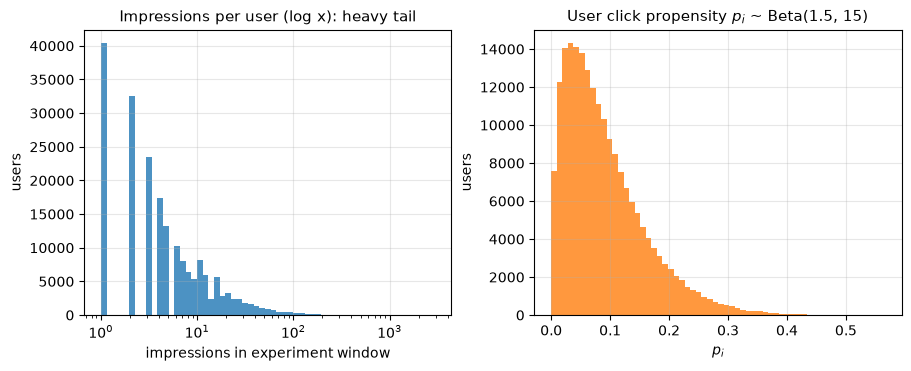

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].hist(m0, bins=np.geomspace(1, m0.max(), 60), color="tab:blue", alpha=0.8)
axes[0].set_xscale("log")
axes[0].set_title("Impressions per user (log x): heavy tail")
axes[0].set_xlabel("impressions in experiment window")
axes[0].set_ylabel("users")
axes[1].hist(p0, bins=60, color="tab:orange", alpha=0.8)
axes[1].set_title("User click propensity $p_i$ ~ Beta(1.5, 15)")
axes[1].set_xlabel("$p_i$")
axes[1].set_ylabel("users")
plt.show()

### The A/A stress test

The cleanest way to expose a broken test is an **A/A study**: simulate thousands of
experiments with *no treatment effect*, run the analysis, and count how often it claims
significance at $\alpha = 0.05$. A correct test rejects ~5% of the time; anything more
is false-positive inflation you would ship to your stakeholders as "wins".

For every simulated A/A (8,000 users, split 50/50) we record three analyses:

1. **Naive impression-level z-test** — pools all impressions per arm, two-proportion
   z-test with $N$ = impressions (the broken one).
2. **Delta method** on user-level totals (derived in Section 2).
3. **t-test on per-user CTRs** — mean of $Y_i/M_i$ per arm (a *different estimand*,
   Section 3, but a valid test of its own null).

4,000 A/A experiments, 8,000 users each, NO true effect
naive impression-level z-test false-positive rate: 29.6% +/- 0.7%  (nominal: 5%)


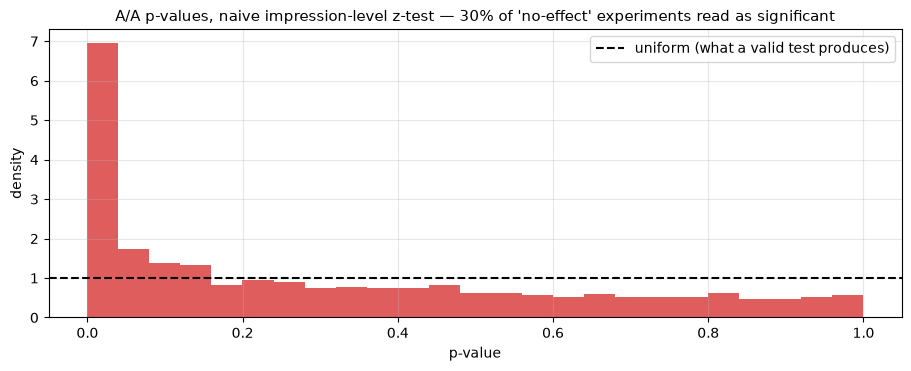

In [4]:
def aa_study(n_sims, n_users, gen, rng):
    """A/A simulations; returns per-sim estimates, SEs and p-values for all 3 tests."""
    out = np.empty((n_sims, 8))
    for i in range(n_sims):
        m, p, y = gen(n_users, rng)
        t = rng.random(n_users) < 0.5
        mt, yt, mc, yc = m[t], y[t], m[~t], y[~t]
        d, se_d = delta_ratio_diff(yt, mt, yc, mc)          # delta method
        rc, se_rc = delta_ratio(yc, mc)                     # control arm alone
        Nt, Nc = mt.sum(), mc.sum()
        p_pool = (yt.sum() + yc.sum()) / (Nt + Nc)          # naive impression z
        se_n = np.sqrt(p_pool * (1 - p_pool) * (1 / Nt + 1 / Nc))
        du, se_u = welch(yt / mt, yc / mc)                  # per-user CTR t-test
        out[i] = (d, se_n, se_d, rc, se_rc, zp(d, se_n), zp(d, se_d), zp(du, se_u))
    return pd.DataFrame(out, columns=["diff", "se_naive", "se_delta", "r_ctrl",
                                      "se_ctrl", "p_naive", "p_delta", "p_user"])


N_AA, N_USERS = 4000, 8000
aa_C = aa_study(N_AA, N_USERS, gen_users, rng)

fpr_naive = (aa_C["p_naive"] < 0.05).mean()
mc_se = np.sqrt(fpr_naive * (1 - fpr_naive) / N_AA)
print(f"{N_AA:,} A/A experiments, {N_USERS:,} users each, NO true effect")
print(f"naive impression-level z-test false-positive rate: "
      f"{fpr_naive:.1%} +/- {mc_se:.1%}  (nominal: 5%)")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(aa_C["p_naive"], bins=25, density=True, color="tab:red", alpha=0.75)
ax.axhline(1, color="k", ls="--", label="uniform (what a valid test produces)")
ax.set_title(f"A/A p-values, naive impression-level z-test — "
             f"{fpr_naive:.0%} of 'no-effect' experiments read as significant")
ax.set_xlabel("p-value")
ax.set_ylabel("density")
ax.legend()
plt.show()

A **six-fold** inflation: roughly 3 out of 10 no-op experiments would be reported as
stat-sig movements of CTR. This is not an exotic corner case — it is the default outcome
of clicking "z-test" on session- or impression-level data in any tool, and it is why
experimentation platforms treat the randomization unit as sacred.

### Why exactly this much: the design effect

For cluster sizes $M_i$ and intra-cluster correlation $\rho$ (here: the correlation
between two impressions of the same user, $\rho = \mathrm{var}(p_i)/(\bar p(1-\bar p))$),
the variance of the impression-pooled estimator is inflated over the i.i.d. binomial
variance by the **design effect**

$$\mathrm{DEFF} \;=\; 1 + (\tilde m - 1)\,\rho, \qquad
  \tilde m = \frac{\mathbb E[M^2]}{\mathbb E[M]},$$

where $\tilde m$ is the **size-weighted** mean cluster size — the expected cluster size
of the user behind a *randomly chosen impression*. With heavy-tailed usage
$\tilde m \gg \bar m$: the average user has ~8 impressions, but the average *impression*
comes from a user with ~46. Since the naive z-statistic is really
$\mathcal N(0, \mathrm{DEFF})$ under $H_0$, the predicted false-positive rate is
$2\Phi(-1.96/\sqrt{\mathrm{DEFF}})$ — checkable against the simulation.

In [5]:
rho_icc = (A_BETA * B_BETA / ((A_BETA + B_BETA) ** 2 * (A_BETA + B_BETA + 1))) / (
    (A_BETA / (A_BETA + B_BETA)) * (B_BETA / (A_BETA + B_BETA)))
m_big = 1 + rng.poisson(np.exp(MU_LOG + SIG_LOG * rng.normal(size=1_000_000)))
m_tilde = (m_big.astype(float) ** 2).sum() / m_big.sum()
deff_pred = 1 + (m_tilde - 1) * rho_icc
deff_emp = (aa_C["diff"].std(ddof=1) / aa_C["se_naive"].mean()) ** 2
fpr_pred = 2 * Z.cdf(-1.96 / np.sqrt(deff_pred))

print(f"intra-user correlation (ICC)    rho    = {rho_icc:.4f}   (tiny!)")
print(f"mean cluster size               m_bar  = {m_big.mean():.1f}")
print(f"size-weighted cluster size      m_tild = {m_tilde:.1f}")
print(f"design effect  predicted 1+(m_tild-1)rho = {deff_pred:.2f}")
print(f"design effect  empirical (true var/naive var) = {deff_emp:.2f}")
print(f"naive SE understates the truth by sqrt(DEFF) = {np.sqrt(deff_emp):.2f}x")
print(f"predicted naive FPR 2*Phi(-1.96/sqrt(DEFF))  = {fpr_pred:.1%}")
print(f"simulated naive FPR                          = {fpr_naive:.1%}")

intra-user correlation (ICC)    rho    = 0.0571   (tiny!)
mean cluster size               m_bar  = 8.2
size-weighted cluster size      m_tild = 45.6
design effect  predicted 1+(m_tild-1)rho = 3.55
design effect  empirical (true var/naive var) = 3.74
naive SE understates the truth by sqrt(DEFF) = 1.93x
predicted naive FPR 2*Phi(-1.96/sqrt(DEFF))  = 29.8%
simulated naive FPR                          = 29.6%


The theory nails the simulation. Note the anatomy of the disaster: the ICC is *tiny*
(ρ ≈ 0.057 — knowing the user explains ~6% of a single impression's variance), but it
multiplies a size-weighted cluster size of ~46. **Small ICC × big clusters = broken
test.** This is also why the required sample size for an impression-level metric scales
with DEFF — see [02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb): a
power analysis that ignores clustering will undersize the experiment by the same factor.

## 2. The delta method for a ratio of means

Aggregate to the randomization unit: user $i$ contributes totals $(Y_i, X_i)$ — clicks
and impressions — which **are** i.i.d. across users (any dependence structure *within* a
user is fine; it's swallowed by the totals). The metric is a ratio of two sample means:

$$\hat R = \frac{\sum_i Y_i}{\sum_i X_i} = \frac{\bar Y}{\bar X}.$$

$\hat R$ is a smooth function $g(\bar Y, \bar X) = \bar Y/\bar X$ of two means, so
first-order Taylor expansion around $(\mu_Y, \mu_X)$ gives

$$\hat R - R \;\approx\; \frac{1}{\mu_X}\Bigl[(\bar Y - \mu_Y) - R\,(\bar X - \mu_X)\Bigr]
  \quad\Longrightarrow\quad
  \operatorname{Var}(\hat R) \;\approx\; \frac{1}{n\,\mu_X^2}
  \Bigl(\sigma_Y^2 - 2R\,\sigma_{XY} + R^2 \sigma_X^2\Bigr).$$

Plug in sample moments and you have the `delta_ratio` helper from the setup cell. The
treatment effect is a difference of two independent ratios, so SEs add in quadrature.
Two properties worth saying out loud in an interview:

- It needs only **first and second moments of user-level totals** — one `GROUP BY user`
  away in SQL, no user-level resampling, embarrassingly parallel. That's why every major
  platform (Microsoft ExP, Netflix, Uber, LinkedIn) ships it as the default for ratio
  metrics.
- Users with $X_i = 0$ (no sessions this week) stay in the analysis with totals
  $(0, 0)$ — no dropping, no 0/0.

Let's validate it on the stored A/A ensemble: the *true* sampling SD of the estimator
(across 4,000 replications) vs the average estimated SE.

                      true sampling SD  mean delta SE  mean naive SE  delta SE / truth  naive SE / truth
quantity                                                                                                
diff of ratios (A/A)           0.00433        0.00421        0.00224           0.97171           0.51712
control-arm ratio              0.00303        0.00296            NaN           0.97643               NaN

A/A false-positive rate, delta-method z-test: 5.5% (nominal 5%)
A/A false-positive rate, per-user CTR t-test:  4.7% (nominal 5%)
=> 95% CI coverage in A/A = 1 - FPR: delta 94.5%, naive 70.4%


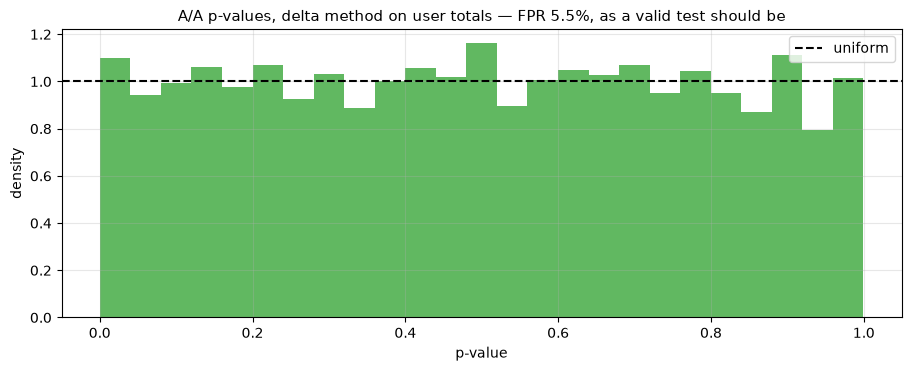

In [6]:
fpr_delta = (aa_C["p_delta"] < 0.05).mean()
fpr_user = (aa_C["p_user"] < 0.05).mean()

val = pd.DataFrame({
    "quantity": ["diff of ratios (A/A)", "control-arm ratio"],
    "true sampling SD": [aa_C["diff"].std(ddof=1), aa_C["r_ctrl"].std(ddof=1)],
    "mean delta SE": [aa_C["se_delta"].mean(), aa_C["se_ctrl"].mean()],
    "mean naive SE": [aa_C["se_naive"].mean(), np.nan],
}).set_index("quantity")
val["delta SE / truth"] = val["mean delta SE"] / val["true sampling SD"]
val["naive SE / truth"] = val["mean naive SE"] / val["true sampling SD"]
print(val.round(5).to_string())
print(f"\nA/A false-positive rate, delta-method z-test: {fpr_delta:.1%} (nominal 5%)")
print(f"A/A false-positive rate, per-user CTR t-test:  {fpr_user:.1%} (nominal 5%)")
print("=> 95% CI coverage in A/A = 1 - FPR: "
      f"delta {1 - fpr_delta:.1%}, naive {1 - fpr_naive:.1%}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(aa_C["p_delta"], bins=25, density=True, color="tab:green", alpha=0.75)
ax.axhline(1, color="k", ls="--", label="uniform")
ax.set_title(f"A/A p-values, delta method on user totals — FPR {fpr_delta:.1%}, "
             "as a valid test should be")
ax.set_xlabel("p-value")
ax.set_ylabel("density")
ax.legend()
plt.show()

The delta SE tracks the true sampling SD within ~1%, its p-values are uniform, and CI
coverage is nominal — while the naive SE understates the truth by the predicted
$\sqrt{\mathrm{DEFF}} \approx 1.9$.

### The linearization view (and why it unlocks everything else)

Rearranged, the delta method says: define the **linearized variable**

$$D_i \;=\; \frac{Y_i - \hat R\, X_i}{\bar X},$$

a plain user-level number. Then $\mathrm{SE}(\hat R) = \mathrm{sd}(D_i)/\sqrt{n}$ —
*identically* the plug-in delta formula, not just asymptotically. So a ratio metric is
secretly an ordinary user-level mean metric, and the whole toolbox for mean metrics
applies to $D_i$: Welch t-tests, CUPED / regression adjustment
([03_variance_reduction_cuped.ipynb](./03_variance_reduction_cuped.ipynb) — production
systems CUPED the linearized metric), and sequential monitoring
([04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb)).

In [7]:
m1, p1, y1 = gen_users(50_000, rng)
r_hat, se_delta_direct = delta_ratio(y1, m1)
d_lin = (y1 - r_hat * m1) / m1.mean()
se_from_lin = d_lin.std(ddof=1) / np.sqrt(m1.size)
print(f"delta-method SE        : {se_delta_direct:.8f}")
print(f"SE of linearized D_i   : {se_from_lin:.8f}")
print(f"agreement              : {se_from_lin / se_delta_direct:.10f} (exact identity)")
print(f"mean of D_i            : {d_lin.mean():.2e} (centered at 0 by construction)")

delta-method SE        : 0.00083841
SE of linearized D_i   : 0.00083841
agreement              : 1.0000000000 (exact identity)
mean of D_i            : 1.60e-18 (centered at 0 by construction)


### How bad is naive, as a function of heterogeneity?

The inflation is not a constant of nature — it is exactly as large as your users are
unequal. Three platforms, same A/A machinery: (A) perfectly homogeneous users (equal
usage, equal $p$), (B) heterogeneous CTRs but equal usage, (C) heterogeneous CTRs and
heavy-tailed usage (our platform).

In [8]:
def gen_homog(n, rng):
    m = np.full(n, 7)
    p = np.full(n, 0.09)
    return m, p, rng.binomial(m, p)


def gen_hetero_p(n, rng):
    m = np.full(n, 7)
    p = rng.beta(A_BETA, B_BETA, n)
    return m, p, rng.binomial(m, p)


aa_A = aa_study(1500, N_USERS, gen_homog, rng)
aa_B = aa_study(1500, N_USERS, gen_hetero_p, rng)

fpr_tbl = pd.DataFrame({
    "naive impression z": [(df["p_naive"] < .05).mean() for df in (aa_A, aa_B, aa_C)],
    "delta method": [(df["p_delta"] < .05).mean() for df in (aa_A, aa_B, aa_C)],
    "per-user CTR t": [(df["p_user"] < .05).mean() for df in (aa_A, aa_B, aa_C)],
}, index=["A: homogeneous users", "B: heterogeneous CTR, equal usage",
          "C: heterogeneous CTR + heavy-tailed usage"])
print("A/A false-positive rate at alpha = 5%:")
print(fpr_tbl.map(lambda v: f"{v:.1%}").to_string())
deff_B = 1 + (7 - 1) * rho_icc
print(f"\nscenario B predicted FPR at DEFF = 1 + 6*rho = {deff_B:.2f}: "
      f"{2 * Z.cdf(-1.96 / np.sqrt(deff_B)):.1%}")

A/A false-positive rate at alpha = 5%:
                                          naive impression z delta method per-user CTR t
A: homogeneous users                                    4.0%         4.1%           4.1%
B: heterogeneous CTR, equal usage                       7.5%         4.5%           4.5%
C: heterogeneous CTR + heavy-tailed usage              29.6%         5.5%           4.7%

scenario B predicted FPR at DEFF = 1 + 6*rho = 1.34: 9.1%


The naive test is exactly right in scenario A — if the analysis unit really is i.i.d.,
there is nothing to fix. It drifts to ~9% with CTR heterogeneity alone and explodes once
usage is heavy-tailed. The delta method and the user-level t-test hold 5% everywhere.
**The failure is a property of your population, so measure it on your own platform with
an A/A (or re-randomization) study — don't assume.**

## 3. One experiment, analyzed four ways

Now a single realistic experiment, with a twist that matters for the estimand question:
on real platforms **usage and CTR are correlated** — heavy users click at lower rates
(ad blindness, habitual scrolling). We build the population with a Gaussian copula
(marginals unchanged: usage stays log-normal-ish, $p_i$ stays Beta(1.5, 15), latent
correlation −0.55) and give treatment a **true +10% relative lift** on every user's
click propensity. 80,000 users.

In [9]:
CORR_USAGE_CTR = -0.55
TRUE_LIFT = 0.10


def gen_platform_corr(n, rng, corr=CORR_USAGE_CTR):
    z = rng.normal(size=n)
    m = 1 + rng.poisson(np.exp(MU_LOG + SIG_LOG * z))
    w = corr * z + np.sqrt(1 - corr**2) * rng.normal(size=n)
    p = st.beta.ppf(Z.cdf(w), A_BETA, B_BETA)   # copula: Beta marginal, corr w/ usage
    return m, p


# ground truth for this population, by brute force (2M users)
mt_big, pt_big = gen_platform_corr(2_000_000, rng)
R_TRUE = (mt_big * pt_big).sum() / mt_big.sum()       # impression-weighted mean of p
DIFF_TRUE = TRUE_LIFT * R_TRUE                        # uniform relative lift scales R
print(f"population truth: impression-weighted CTR {R_TRUE:.4f}, "
      f"user-mean CTR {pt_big.mean():.4f}")
print(f"true treatment effect on CTR: +{DIFF_TRUE:.4f} ({TRUE_LIFT:+.0%} relative)\n")

n_exp = 80_000
m_e, p_e = gen_platform_corr(n_exp, rng)
t_e = rng.random(n_exp) < 0.5
y_e = rng.binomial(m_e, np.clip(p_e * np.where(t_e, 1 + TRUE_LIFT, 1.0), 0, 1))

yt_e, mt_e = y_e[t_e].astype(float), m_e[t_e].astype(float)
yc_e, mc_e = y_e[~t_e].astype(float), m_e[~t_e].astype(float)
d_hat, se_d = delta_ratio_diff(yt_e, mt_e, yc_e, mc_e)
rt_hat, _ = delta_ratio(yt_e, mt_e)
rc_hat, _ = delta_ratio(yc_e, mc_e)
print(f"experiment: {n_exp:,} users, {int(m_e.sum()):,} impressions")
print(f"CTR treatment {rt_hat:.4f} vs control {rc_hat:.4f}")
print(f"delta method: diff {d_hat * 100:+.3f}pp +/- {1.96 * se_d * 100:.3f}pp, "
      f"z = {d_hat / se_d:.2f}, p = {zp(d_hat, se_d):.2e}")
print(f"(true diff {DIFF_TRUE * 100:+.3f}pp — inside the CI: "
      f"{ci95(d_hat, se_d)[0] < DIFF_TRUE < ci95(d_hat, se_d)[1]})")

population truth: impression-weighted CTR 0.0545, user-mean CTR 0.0909
true treatment effect on CTR: +0.0055 (+10% relative)



experiment: 80,000 users, 660,734 impressions
CTR treatment 0.0598 vs control 0.0546
delta method: diff +0.512pp +/- 0.185pp, z = 5.43, p = 5.78e-08
(true diff +0.545pp — inside the CI: True)


### 3.1 Ratio-of-averages vs average-of-ratios: two metrics, one name

There are two natural "CTRs" and they are **different estimands**:

$$\underbrace{\frac{\mathbb E[Y_i]}{\mathbb E[X_i]}}_{\text{ratio of averages:}\ \ \text{CTR of the *impression* population}}
  \qquad \text{vs} \qquad
  \underbrace{\mathbb E\!\left[\frac{Y_i}{X_i}\right]}_{\text{average of ratios:}\ \ \text{CTR of the *user* population}}$$

The first weights users by their impression volume; the second weights every user
equally. They coincide only when the per-user ratio is uncorrelated with the
denominator. On our (realistic, negatively correlated) platform they are *very* far
apart:

control arm, same users, same clicks:
  ratio of averages  (impression-weighted CTR): 0.0546
  average of ratios  (mean per-user CTR):       0.0914  (+67%)


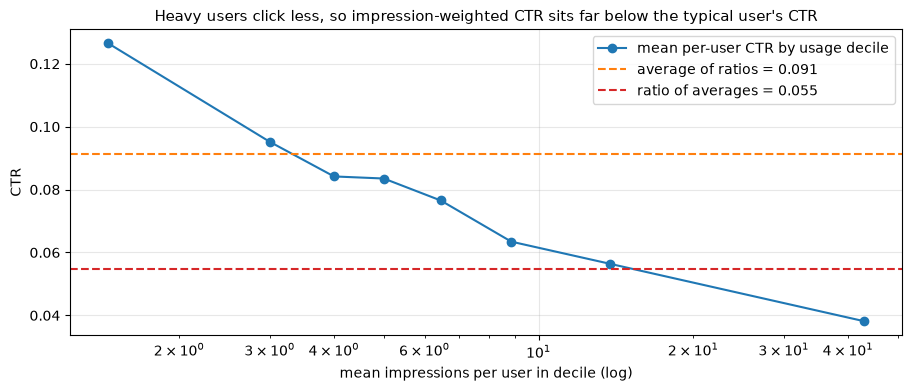

In [10]:
r_user_c = yc_e / mc_e                       # per-user CTRs, control arm
print(f"control arm, same users, same clicks:")
print(f"  ratio of averages  (impression-weighted CTR): {rc_hat:.4f}")
print(f"  average of ratios  (mean per-user CTR):       {r_user_c.mean():.4f}  "
      f"({r_user_c.mean() / rc_hat - 1:+.0%})")

dec = pd.qcut(mc_e, 10, labels=False, duplicates="drop")
prof = pd.DataFrame({"decile": dec, "r": r_user_c, "m": mc_e}).groupby("decile").agg(
    mean_ctr=("r", "mean"), mean_imps=("m", "mean"))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(prof["mean_imps"], prof["mean_ctr"], "o-", color="tab:blue",
        label="mean per-user CTR by usage decile")
ax.axhline(r_user_c.mean(), color="tab:orange", ls="--",
           label=f"average of ratios = {r_user_c.mean():.3f}")
ax.axhline(rc_hat, color="tab:red", ls="--",
           label=f"ratio of averages = {rc_hat:.3f}")
ax.set_xscale("log")
ax.set_xlabel("mean impressions per user in decile (log)")
ax.set_ylabel("CTR")
ax.set_title("Heavy users click less, so impression-weighted CTR sits far below the "
             "typical user's CTR")
ax.legend()
plt.show()

Neither number is wrong — they answer different questions, and a senior candidate picks
the estimand *before* the estimator:

- **Ratio of averages** (ratio-of-sums) is the right metric when value scales with
  events: ad revenue (every impression is sellable inventory), delivery cost per order,
  fill rate. It is what finance reconciles against.
- **Average of ratios** is the right metric when the *user experience* is the product:
  "what CTR does the typical user experience?" It refuses to let one power user drag the
  metric; equivalently, it is the ATE on the user-level outcome $Y_i/X_i$. Its costs:
  undefined for $X_i = 0$ users (you must decide: drop? impute 0? — an estimand change
  either way) and noisy for small-$X_i$ users (a 1-impression user has CTR 0% or 100%).
- The gap between the two is itself diagnostic: it exists exactly when usage correlates
  with the ratio — which also means **any treatment that shifts usage shifts the
  ratio-of-sums metric through composition alone** (Section 6, Pitfall 1).

### 3.2 The user-level (cluster) bootstrap

The nonparametric alternative to the delta method: resample **users** (clusters) with
replacement, recompute the ratio-of-sums each time — never resample impressions
(Pitfall 2 shows what happens if you do). This is the same bootstrap logic as
[../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb),
with the resampling unit promoted to the independence unit. At industrial scale you
don't materialize resamples: give each user a $\mathrm{Poisson}(1)$ weight per replicate
(≈ multinomial resampling) and accumulate weighted sums in one streaming pass — that is
how Google/Spotify-style pipelines bootstrap terabytes, and it shards trivially in
Spark ([../07_sql_and_big_data/03_pyspark_fundamentals.ipynb](../07_sql_and_big_data/03_pyspark_fundamentals.ipynb)).

cluster bootstrap (2000 resamples): SE 0.095pp (delta: 0.094pp)
percentile CI [+0.327, +0.698]pp


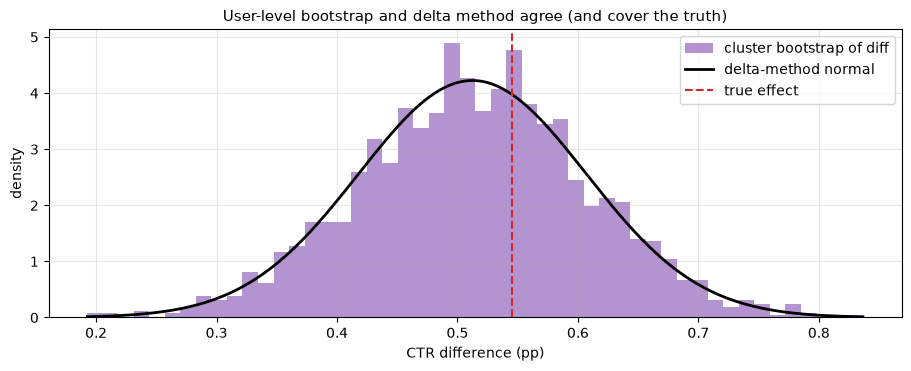

In [11]:
B = 2000
rt_b, rc_b = np.empty(B), np.empty(B)
nt, nc = yt_e.size, yc_e.size
for b in range(B):
    it = rng.integers(0, nt, nt)               # resample users within each arm
    ic = rng.integers(0, nc, nc)
    rt_b[b] = yt_e[it].sum() / mt_e[it].sum()
    rc_b[b] = yc_e[ic].sum() / mc_e[ic].sum()
d_b = rt_b - rc_b
boot_se = d_b.std(ddof=1)
boot_ci = np.quantile(d_b, [0.025, 0.975])
print(f"cluster bootstrap ({B} resamples): SE {boot_se * 100:.3f}pp "
      f"(delta: {se_d * 100:.3f}pp)")
print(f"percentile CI [{boot_ci[0] * 100:+.3f}, {boot_ci[1] * 100:+.3f}]pp")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(d_b * 100, bins=50, density=True, color="tab:purple", alpha=0.7,
        label="cluster bootstrap of diff")
grid = np.linspace(d_b.min(), d_b.max(), 300)
ax.plot(grid * 100, Z.pdf(grid, d_hat, se_d) / 100, "k-", lw=2,
        label="delta-method normal")
ax.axvline(DIFF_TRUE * 100, color="tab:red", ls="--", label="true effect")
ax.set_title("User-level bootstrap and delta method agree (and cover the truth)")
ax.set_xlabel("CTR difference (pp)")
ax.set_ylabel("density")
ax.legend()
plt.show()

### 3.3 The scorecard, side by side

In [12]:
du_hat, se_u = welch(yt_e / mt_e, yc_e / mc_e)     # per-user averaging (other estimand!)
Nt_e, Nc_e = mt_e.sum(), mc_e.sum()
p_pool_e = (yt_e.sum() + yc_e.sum()) / (Nt_e + Nc_e)
se_naive_e = np.sqrt(p_pool_e * (1 - p_pool_e) * (1 / Nt_e + 1 / Nc_e))


def row(est, se, lo=None, hi=None):
    lo, hi = (lo, hi) if lo is not None else ci95(est, se)
    return (f"{est * 100:+.3f}", f"{se * 100:.3f}",
            f"[{lo * 100:+.3f}, {hi * 100:+.3f}]", f"{zp(est, se):.1e}")


methods = pd.DataFrame([
    ("naive impression z", "ratio of averages", "NO (SE ~1.9x too small)",
     *row(d_hat, se_naive_e)),
    ("delta method", "ratio of averages", "yes", *row(d_hat, se_d)),
    ("user-level bootstrap", "ratio of averages", "yes",
     *row(d_hat, boot_se, boot_ci[0], boot_ci[1])),
    ("per-user CTR t-test", "AVERAGE OF RATIOS (different!)", "yes, for its estimand",
     *row(du_hat, se_u)),
], columns=["method", "estimand", "valid SE?", "estimate (pp)", "SE (pp)",
            "95% CI (pp)", "p"]).set_index("method")
print(methods.to_string())
print(f"\ntrue effect, ratio-of-averages estimand: {DIFF_TRUE * 100:+.3f}pp")
print(f"true effect, average-of-ratios estimand:  {TRUE_LIFT * pt_big.mean() * 100:+.3f}pp")

                                            estimand                valid SE? estimate (pp) SE (pp)       95% CI (pp)        p
method                                                                                                                        
naive impression z                 ratio of averages  NO (SE ~1.9x too small)        +0.512   0.057  [+0.400, +0.624]  3.0e-19
delta method                       ratio of averages                      yes        +0.512   0.094  [+0.327, +0.698]  5.8e-08
user-level bootstrap               ratio of averages                      yes        +0.512   0.095  [+0.327, +0.698]  6.5e-08
per-user CTR t-test   AVERAGE OF RATIOS (different!)    yes, for its estimand        +0.829   0.150  [+0.535, +1.122]  3.2e-08



true effect, ratio-of-averages estimand: +0.545pp
true effect, average-of-ratios estimand:  +0.909pp


Read the table the way an interviewer would want you to:

- Rows 1–3 estimate the **same number**; only the uncertainty differs. The naive CI is
  ~1.9× too narrow — same point estimate, dishonest precision.
- Delta and cluster bootstrap agree closely — pick delta for scale/simplicity, the
  bootstrap when you distrust the first-order approximation (tiny n, extreme tails, or
  weird statistics like quantiles — Section 5).
- The per-user t-test is a *different metric* that here reads roughly twice the
  absolute effect (the relative lift is +10% for every user, and the user-weighted
  baseline is ~9% vs ~5.5% impression-weighted). Reporting it as "CTR" next to last
  week's ratio-of-sums dashboard number is an estimand switch, not a variance trick.

## 4. Cluster-robust regression and cluster-randomized designs

The delta method is a special case of a general principle: **sum the contributions
within each independence unit first, then treat those sums as i.i.d.** That is exactly
what cluster-robust (sandwich) variance estimators do in a regression. So running OLS at
the *impression* level, `click ~ treatment`, with SEs clustered by user, must reproduce
the delta method — and the identical point estimate shows the estimate was never the
problem, only the SE:

In [13]:
uid_row = np.repeat(np.arange(n_exp), m_e)
t_row = np.repeat(t_e, m_e).astype(float)
first_row = np.repeat(np.cumsum(m_e) - m_e, m_e)          # index of user's first row
click_row = (np.arange(m_e.sum()) - first_row < np.repeat(y_e, m_e)).astype(float)

X_ols = sm.add_constant(t_row)
ols_iid = sm.OLS(click_row, X_ols).fit()
ols_cl = sm.OLS(click_row, X_ols).fit(cov_type="cluster",
                                      cov_kwds={"groups": uid_row})
reg_tbl = pd.DataFrame({
    "estimate (pp)": [ols_iid.params[1] * 100, ols_cl.params[1] * 100,
                      d_hat * 100, d_hat * 100],
    "SE (pp)": [ols_iid.bse[1] * 100, ols_cl.bse[1] * 100,
                se_naive_e * 100, se_d * 100],
}, index=["OLS impression-level, iid SE", "OLS impression-level, cluster-by-user SE",
          "naive z (for reference)", "delta method (for reference)"])
print(f"{click_row.size:,} impression rows, {n_exp:,} user clusters")
print(reg_tbl.round(4).to_string())

660,734 impression rows, 80,000 user clusters
                                          estimate (pp)  SE (pp)
OLS impression-level, iid SE                     0.5124   0.0571
OLS impression-level, cluster-by-user SE         0.5124   0.0944
naive z (for reference)                          0.5124   0.0571
delta method (for reference)                     0.5124   0.0944


iid OLS ≈ naive z; cluster-robust OLS ≈ delta method. The regression framing is what
you reach for when you want more: covariate adjustment (CUPED-style, at the user level),
heterogeneous effects, or multiple treatments — see
[../01_statistical_foundations/03_regression_the_workhorse.ipynb](../01_statistical_foundations/03_regression_the_workhorse.ipynb)
for the cluster-robust machinery itself.

**Cluster-randomized designs are the same math with a scarier $n$.** When you randomize
*cities, stores, or classrooms* (because of interference — treated users contaminate
control users), every metric becomes a ratio over cluster totals and the delta
method/cluster-robust SEs apply with clusters as the unit. The catch: $n$ is now the
number of clusters, often 20–100, so normal approximations fray — use $t_{G-1}$
references, and for few clusters wild-cluster bootstrap or permutation tests. Geo
experiments, switchbacks, and marketplace designs are treated properly in
[06_advanced_designs_interference.ipynb](./06_advanced_designs_interference.ipynb);
the same "few clusters" caution powers the DiD inference discussion in
[../03_causal_inference/03_did_synthetic_control.ipynb](../03_causal_inference/03_did_synthetic_control.ipynb).

## 5. Percentile metrics: p90 latency needs its own treatment

Latency SLOs are quantiles ("p90 < 300ms"), and quantiles are not smooth functions of
per-user *sums*, so the ratio-metric delta method does not apply directly. Two separate
problems stack up:

1. Even for i.i.d. data, the sample quantile's variance
   $\;q(1-q)\,/\,\bigl(n f(\xi_q)^2\bigr)\;$ involves the **density at the quantile** —
   not estimable by a variance formula you can trust blindly. The standard i.i.d. answer
   is the distribution-free order-statistic CI (pick order statistics via binomial
   quantiles).
2. Requests cluster within users (a user's device/network makes all their requests fast
   or slow together). The order-statistic CI assumes exchangeable requests and becomes
   aggressively anti-conservative — same disease as Section 1, no delta-method cure.

We simulate request latency with a persistent per-user speed factor
(log-normal, ICC ≈ 0.67 on log-latency) so the true request-level p90 is known in
closed form, then check coverage of both CIs. The remedy is again **resample users, not
requests** — a weighted-quantile Poisson bootstrap.

In [14]:
SIG_USER, SIG_REQ, BASE_MS = 0.5, 0.35, 120.0
TRUE_P90 = BASE_MS * np.exp(np.hypot(SIG_USER, SIG_REQ) * Z.ppf(0.90))


def sim_latency(n_users, rng):
    """Requests clustered by user: latency = base * user_factor * request_noise."""
    u = np.exp(rng.normal(0.0, SIG_USER, n_users))
    k = 1 + rng.poisson(6.0, n_users)
    uid = np.repeat(np.arange(n_users), k)
    lat = BASE_MS * u[uid] * np.exp(rng.normal(0.0, SIG_REQ, uid.size))
    return uid, lat


def orderstat_ci(x_sorted, q, conf=0.95):
    """Distribution-free CI for the q-quantile assuming iid observations."""
    n = x_sorted.size
    a = (1 - conf) / 2
    lo = int(st.binom.ppf(a, n, q))
    hi = int(st.binom.ppf(1 - a, n, q)) + 1
    return x_sorted[max(lo - 1, 0)], x_sorted[min(hi - 1, n - 1)]


def cluster_boot_quantile(uid, lat, n_users, q, B, rng):
    """User-level Poisson-weight bootstrap of a request-level quantile."""
    order = np.argsort(lat)
    ls, us = lat[order], uid[order]
    W = rng.poisson(1.0, (B, n_users))         # one weight per user per replicate
    wr = W[:, us]                              # weight of each request = its user's
    cw = np.cumsum(wr, axis=1)
    idx = (cw >= q * cw[:, -1][:, None]).argmax(axis=1)
    return ls[idx]


uid_l, lat_l = sim_latency(1500, rng)
xs_l = np.sort(lat_l)
p90_hat = np.quantile(lat_l, 0.9)
ci_naive = orderstat_ci(xs_l, 0.9)
bq = cluster_boot_quantile(uid_l, lat_l, 1500, 0.9, 400, rng)
ci_boot = np.quantile(bq, [0.025, 0.975])
per_user_p90 = pd.Series(lat_l).groupby(uid_l).quantile(0.9)
print(f"one dataset: {lat_l.size:,} requests from 1,500 users; true p90 = {TRUE_P90:.1f}ms")
print(f"p90 estimate {p90_hat:.1f}ms")
print(f"  iid order-statistic CI: [{ci_naive[0]:.1f}, {ci_naive[1]:.1f}]ms "
      f"(width {ci_naive[1] - ci_naive[0]:.1f})")
print(f"  user-bootstrap CI:      [{ci_boot[0]:.1f}, {ci_boot[1]:.1f}]ms "
      f"(width {ci_boot[1] - ci_boot[0]:.1f})")
print(f"\nestimand check — mean of per-user p90s: {per_user_p90.mean():.1f}ms "
      f"(NOT the p90 of traffic, {p90_hat:.1f}ms: averaging per-user quantiles is a "
      "different metric)")

one dataset: 10,545 requests from 1,500 users; true p90 = 262.3ms
p90 estimate 254.9ms
  iid order-statistic CI: [250.7, 259.7]ms (width 9.0)
  user-bootstrap CI:      [246.0, 265.0]ms (width 18.9)

estimand check — mean of per-user p90s: 190.8ms (NOT the p90 of traffic, 254.9ms: averaging per-user quantiles is a different metric)


In [15]:
def latency_coverage(q, true_q, n_sims, n_users, B, rng):
    """Coverage of iid order-stat CI vs user-bootstrap CI for the q-quantile."""
    cov_n = cov_b = 0
    est = np.empty(n_sims)
    width_n = np.empty(n_sims)
    for i in range(n_sims):
        uid, lat = sim_latency(n_users, rng)
        xs = np.sort(lat)
        est[i] = np.quantile(lat, q)
        lo, hi = orderstat_ci(xs, q)
        width_n[i] = hi - lo
        cov_n += lo <= true_q <= hi
        b = cluster_boot_quantile(uid, lat, n_users, q, B, rng)
        blo, bhi = np.quantile(b, [0.025, 0.975])
        cov_b += blo <= true_q <= bhi
    return cov_n / n_sims, cov_b / n_sims, est.std(ddof=1), width_n.mean()


cov_naive, cov_boot, sd_p90, w_naive = latency_coverage(0.90, TRUE_P90, 200, 1500, 200, rng)
print("coverage of nominal-95% CIs for p90 latency, 200 fresh simulations:")
print(f"  iid order-statistic CI : {cov_naive:.0%}   (mean width {w_naive:.1f}ms, "
      f"vs true sampling SD {sd_p90:.1f}ms -> needs ~{3.92 * sd_p90:.0f}ms)")
print(f"  user-level bootstrap CI: {cov_boot:.0%}")

coverage of nominal-95% CIs for p90 latency, 200 fresh simulations:
  iid order-statistic CI : 70%   (mean width 10.5ms, vs true sampling SD 5.4ms -> needs ~21ms)
  user-level bootstrap CI: 94%


The i.i.d. CI covers the truth well under 95% of the time — its width is sized for
independent requests, and requests are anything but. The user-level bootstrap restores
near-nominal coverage (percentile bootstrap CIs for tail quantiles run a touch
anti-conservative at this scale; with more users it converges). Two practical notes for
the "how do you monitor p90?" interview thread: (a) averaging per-user p90s is a
*different estimand* (the typical user's p90, not the p90 of traffic) — fine if chosen
deliberately, wrong as a silent substitute; (b) a common production dodge is to replace
the quantile with a **threshold rate** — "% of requests over 300ms" — which is a ratio
metric again, and the delta method applies.

## 6. Pitfalls

### Pitfall 1 — the treatment moved the denominator

A ratio metric's denominator is a *post-treatment quantity*. If treatment changes it,
the ratio confounds "value per event" with "mix of events" — dividing by a
post-treatment variable is the same sin as conditioning on one
([../03_causal_inference/01_potential_outcomes_dags.ipynb](../03_causal_inference/01_potential_outcomes_dags.ipynb)).
Classic case: an engagement feature (say infinite scroll) lifts sessions +10%, and the
marginal sessions monetize slightly worse (session conversion 15% → 14.2%). Every
readout below is *correct*; the trap is purely interpretive — "revenue per session
dropped 4%" sounds like a loss, while the business actually gained:

In [16]:
n_p1 = 120_000
lam_p1 = rng.gamma(1.2, 2.5, n_p1)                     # mean 3 sessions/user
spend_mult = rng.lognormal(-0.18, 0.6, n_p1)           # persistent spender level, mean 1
conv_u = rng.beta(1.2, 6.8, n_p1)                      # per-session conversion, mean .15
t_p1 = rng.random(n_p1) < 0.5

s_p1 = rng.poisson(lam_p1 * np.where(t_p1, 1.10, 1.0))          # sessions: +10%
uid_s1 = np.repeat(np.arange(n_p1), s_p1)
sess_t1 = t_p1[uid_s1]
conv_row = rng.random(uid_s1.size) < conv_u[uid_s1] * np.where(sess_t1, 0.142 / 0.15, 1)
amt_row = np.where(conv_row,
                   30 * spend_mult[uid_s1] * rng.lognormal(-0.18, 0.6, uid_s1.size), 0.0)
rev_p1 = np.bincount(uid_s1, weights=amt_row, minlength=n_p1)
s_p1f = s_p1.astype(float)


def report(name, d, se, base):
    lo, hi = ci95(d, se)
    print(f"  {name:<22s} {d / base:+7.1%}  CI [{lo / base:+.1%}, {hi / base:+.1%}]"
          f"  p = {zp(d, se):.1e}")


d_sess, se_sess = welch(s_p1f[t_p1], s_p1f[~t_p1])
d_rev, se_rev = welch(rev_p1[t_p1], rev_p1[~t_p1])
d_rps, se_rps = delta_ratio_diff(rev_p1[t_p1], s_p1f[t_p1], rev_p1[~t_p1], s_p1f[~t_p1])
print(f"{n_p1:,} users; relative effects vs control baseline:")
report("sessions / user", d_sess, se_sess, s_p1f[~t_p1].mean())
report("revenue / user", d_rev, se_rev, rev_p1[~t_p1].mean())
report("revenue / session", d_rps, se_rps, delta_ratio(rev_p1[~t_p1], s_p1f[~t_p1])[0])
print("\nAll three are real effects. 'Revenue per session' fell because the denominator"
      "\ngrew faster than the numerator — the feature ADDED net revenue. Decide on"
      "\nrevenue/user (user-level, causally clean); treat ratios as diagnostics and"
      "\nalways decompose them into numerator and denominator effects.")

120,000 users; relative effects vs control baseline:
  sessions / user         +10.6%  CI [+9.3%, +11.8%]  p = 7.0e-59
  revenue / user           -0.0%  CI [-3.2%, +3.1%]  p = 9.9e-01
  revenue / session        -9.6%  CI [-12.4%, -6.8%]  p = 1.5e-11

All three are real effects. 'Revenue per session' fell because the denominator
grew faster than the numerator — the feature ADDED net revenue. Decide on
revenue/user (user-level, causally clean); treat ratios as diagnostics and
always decompose them into numerator and denominator effects.


### Pitfall 2 — bootstrapping at the wrong unit

"We used the bootstrap, so we're safe" is false comfort: the bootstrap inherits its
independence assumption from the **resampling unit**. Resampling impressions just
re-derives the naive SE with extra compute; only resampling users captures the real
sampling variability. On the Section 3 experiment (where the truth is the delta/cluster
answer):

In [17]:
Bw = 300
click_t_rows = click_row[t_row == 1]
click_c_rows = click_row[t_row == 0]
d_wrong = np.empty(Bw)
for b in range(Bw):
    i1 = rng.integers(0, click_t_rows.size, click_t_rows.size)
    i0 = rng.integers(0, click_c_rows.size, click_c_rows.size)
    d_wrong[b] = click_t_rows[i1].mean() - click_c_rows[i0].mean()
print(f"SE of CTR difference, {Bw} bootstrap replicates each:")
print(f"  impression-level bootstrap: {d_wrong.std(ddof=1) * 100:.3f}pp"
      f"   ~= naive SE {se_naive_e * 100:.3f}pp   (wrong)")
print(f"  user-level bootstrap:       {boot_se * 100:.3f}pp"
      f"   ~= delta SE {se_d * 100:.3f}pp   (right)")
print(f"  ratio wrong/right: {boot_se / d_wrong.std(ddof=1):.2f}x, "
      f"as predicted by sqrt(DEFF)")

SE of CTR difference, 300 bootstrap replicates each:
  impression-level bootstrap: 0.056pp   ~= naive SE 0.057pp   (wrong)
  user-level bootstrap:       0.095pp   ~= delta SE 0.094pp   (right)
  ratio wrong/right: 1.68x, as predicted by sqrt(DEFF)


### Pitfall 3 — conditioning on being in the denominator

Restricting the analysis to "active" users (those with ≥1 session) feels harmless —
after all, per-user ratios are undefined for the rest. But *who is active* is itself a
treatment outcome. If treatment activates marginal users, the two "active" populations
are no longer exchangeable, and any per-user comparison among them is biased — the
triggered-analysis / selection version of the bad-control problem.

Simulation: a re-engagement push multiplies every user's session rate ×1.6 and changes
**nothing else** — each user's per-session conversion $c_i$ is identical in both arms
by construction. Marginal (low-engagement) users convert worse, so the newly activated
dilute the treated active pool:

In [18]:
n_p3 = 300_000
lam_p3 = rng.gamma(0.7, 1.2, n_p3)                     # dormant-heavy user base
c_p3 = 0.02 + 0.28 * (1 - np.exp(-lam_p3))             # engaged users convert better
t_p3 = rng.random(n_p3) < 0.5
s_p3 = rng.poisson(lam_p3 * np.where(t_p3, 1.6, 1.0))  # sessions x1.6, c_i untouched
buy_p3 = rng.binomial(s_p3, c_p3)
s_p3f = s_p3.astype(float)
act = s_p3 > 0

conv_ps = np.zeros(n_p3)
conv_ps[act] = buy_p3[act] / s_p3f[act]                # per-user conversion/session
d_bad, se_bad = welch(conv_ps[act & t_p3], conv_ps[act & ~t_p3])
base_bad = conv_ps[act & ~t_p3].mean()
d_ok, se_ok = delta_ratio_diff(buy_p3[t_p3], s_p3f[t_p3], buy_p3[~t_p3], s_p3f[~t_p3])
d_buy, se_buy = welch(buy_p3[t_p3].astype(float), buy_p3[~t_p3].astype(float))

print(f"share of users with >=1 session: control {act[~t_p3].mean():.1%}, "
      f"treatment {act[t_p3].mean():.1%}  (treatment activated marginal users)")
print("\n'conversion per session', analyzed among ACTIVE users only (per-user t-test):")
print(f"  {d_bad / base_bad:+.1%}, p = {zp(d_bad, se_bad):.4f}  <- looks like the "
      "feature degrades session quality. IT DOES NOT.")
print("\nhonest analyses over ALL randomized users:")
print(f"  conversion/session, ratio of sums + delta: {d_ok * 100:+.3f}pp, "
      f"p = {zp(d_ok, se_ok):.2f}  (truth: exactly 0 by construction)")
print(f"  purchases/user (plain user-level mean):    "
      f"{d_buy / buy_p3[~t_p3].mean():+.1%}, p = {zp(d_buy, se_buy):.1e}  (real win)")

share of users with >=1 session: control 42.4%, treatment 52.9%  (treatment activated marginal users)

'conversion per session', analyzed among ACTIVE users only (per-user t-test):
  -5.6%, p = 0.0000  <- looks like the feature degrades session quality. IT DOES NOT.

honest analyses over ALL randomized users:
  conversion/session, ratio of sums + delta: -0.150pp, p = 0.33  (truth: exactly 0 by construction)
  purchases/user (plain user-level mean):    +58.9%, p = 0.0e+00  (real win)


The conditioned analysis manufactures a significant "quality drop" out of nothing —
pure composition. The all-users ratio-of-sums is null (as constructed: both numerator
and denominator scale ×1.6), and the user-level purchases metric shows the real gain.
Rules: the analysis population is **everyone randomized**; zero-denominator users enter
the sums as $(0,0)$; if you must analyze a triggered subset, trigger on a
**pre-treatment** definition of eligibility.

## Interview corner

**1. "Why can't you run a t-test on CTR at the impression level?"**
The t-test's exchangeable-unit assumption is violated twice: impressions from the same
user are correlated (they share the user's propensity — ICC), and users contribute
wildly different impression counts. Randomization happened at the user level, so the
design's independent unit is the user. Quantify: variance is understated by
$\mathrm{DEFF} = 1 + (\tilde m - 1)\rho$ with $\tilde m$ the size-weighted cluster
size; in our simulation ρ ≈ 0.06 and $\tilde m$ ≈ 46 gave DEFF ≈ 3.6 and a 30% A/A
false-positive rate. Fix: delta method on user totals, cluster bootstrap, or
cluster-robust regression — all agree.

**2. "Ratio of means or mean of ratios — which is 'the CTR'?"**
State that they are different estimands: impression-weighted vs user-weighted, equal
only when the per-user ratio is uncorrelated with usage. Pick by business question —
monetization per event (ads, cost per order) → ratio of sums; typical-user experience →
mean of per-user ratios, accepting the zero-denominator policy and small-denominator
noise. Senior move: mention they diverged 5.5% vs 9.1% in a realistic negatively
correlated population, and that a usage-shifting treatment moves the ratio-of-sums
metric through composition alone.

**3. "How would you compute a CI for revenue per session?"**
Aggregate to the randomization unit: per user, totals $(\text{rev}_i, \text{sess}_i)$,
keeping zero-session users as $(0,0)$. Then either (a) delta method:
$\widehat{\mathrm{Var}} = (S_Y^2 - 2\hat R S_{XY} + \hat R^2 S_X^2)/(n\bar X^2)$, normal
CI, and SEs add in quadrature across arms; or (b) user-level bootstrap (Poisson weights
at scale). Mention the linearized variable $D_i = (Y_i - \hat R X_i)/\bar X$: it turns
the ratio into a mean metric so CUPED and sequential monitoring apply unchanged. Flag
heavy tails → consider winsorizing the *numerator totals* (a deliberate estimand
change, decided pre-registration).

**4. "Revenue per session is −4% but total revenue is up — what happened, do you ship?"**
The denominator moved: sessions grew faster than revenue. A ratio over a post-treatment
denominator is not a per-session causal effect — decompose into numerator and
denominator effects, decide on the user-level metric (revenue/user), and keep the ratio
as a diagnostic. Often this pattern is a *good* outcome: marginal engagement monetizes
below average but adds net revenue.

**5. "When is session-level analysis actually fine?"**
When the analysis unit is the randomization unit (e.g., you randomized queries or
sessions — noting that brings its own problems: inconsistent user experience,
within-user interference), or when clusters are near-equal-sized *and* ICC ≈ 0 —
scenario A in our study. Never assert it; demonstrate it with an A/A or
re-randomization study on your own platform's traffic.

**6. "How do you put a CI on p90 latency?"**
Quantiles have no per-user linearization, and the iid variance needs the density at the
quantile. For iid data use the distribution-free order-statistic CI; under user
clustering that CI badly undercovers (68% vs 95% in our sim), so bootstrap **users**,
recomputing the pooled quantile per replicate (weighted-quantile trick with Poisson
weights at scale). Averaging per-user p90s changes the estimand. Pragmatic alternative:
monitor "% of requests over the SLO threshold" — a ratio metric, delta method applies.

**7. "You're running a geo experiment in 40 cities. How does this chapter apply?"**
Directly: with cluster randomization every metric is a ratio of cluster totals, and the
delta method/cluster-robust SE with $n = 40$ clusters is the analysis. But at 40
clusters the normal approximation is shaky: use $t_{G-1}$, wild-cluster bootstrap, or
permutation/randomization inference, and design with pairing/stratification of geos.
(Details: [06_advanced_designs_interference.ipynb](./06_advanced_designs_interference.ipynb).)

## Key takeaways

- Ratio metrics = ratios of sums with the denominator below the randomization unit.
  Analyze at the unit you randomized; anything else must justify itself.
- Naive impression/session-level tests understate variance by
  $\mathrm{DEFF} = 1 + (\tilde m - 1)\rho$ with the **size-weighted** cluster size —
  tiny ICC × heavy-tailed usage produced DEFF ≈ 3.6 and a 30% A/A false-positive rate.
- Delta method: $\operatorname{Var}(\hat R) \approx
  (\sigma_Y^2 - 2R\sigma_{XY} + R^2\sigma_X^2)/(n\mu_X^2)$ from user totals — validated
  here to ~1% of the true sampling SD; needs only user-level moments; keeps
  zero-denominator users.
- The linearized variable $D_i = (Y_i - \hat R X_i)/\bar X$ makes a ratio metric an
  ordinary mean metric — CUPED, t-tests, and sequential methods apply to it unchanged.
- Ratio-of-averages ≠ average-of-ratios: different weights, different estimands, both
  legitimate. Choose by business question *before* choosing the estimator; the gap is
  large whenever usage correlates with the ratio.
- Cluster bootstrap (resample users; Poisson weights at scale) ≈ delta method; the
  bootstrap only works if the resampling unit is the independence unit.
- Cluster-robust OLS at the event level reproduces the delta method exactly in the
  estimate and asymptotically in the SE — and generalizes to covariates and
  cluster-randomized designs, where $n$ = number of clusters.
- Percentile metrics: no linearization exists; iid order-statistic CIs undercover badly
  under clustering; bootstrap users, or switch to a threshold-rate metric.
- Watch the denominator: treatments move it (decompose numerator/denominator; decide on
  user-level metrics), and conditioning on having a denominator (active users only) is
  selection bias on a post-treatment variable.

## Exercises

**Exercise 1.** Relative lifts are what stakeholders read ("CTR +7.6%"), and the CI for
a *ratio of ratios* $\hat R_T/\hat R_C$ is best built on the log scale. Show that the
delta method gives
$\operatorname{Var}(\log \hat R) \approx \bigl(S_Y^2/\bar Y^2 - 2S_{XY}/(\bar X\bar Y)
+ S_X^2/\bar X^2\bigr)/n$, implement it, compute a 95% CI for the relative CTR lift in
the Section 3 experiment, and check it against the cluster bootstrap (reuse `rt_b`,
`rc_b`) and the true lift (+10%).

In [19]:
# --- Solution ---
# Var(log R) = (grad log R)' Sigma (grad log R) / n with grad = (1/muY, -1/muX):
# the R^2 factor of the plain-scale formula cancels, leaving the CV-style form above.


def delta_log_ratio_se(y, x):
    n = y.size
    my, mx = y.mean(), x.mean()
    dy, dx = y - my, x - mx
    v = (dy @ dy) / my**2 - 2 * (dy @ dx) / (mx * my) + (dx @ dx) / mx**2
    return np.sqrt(v / (n - 1) / n)


se_log = np.hypot(delta_log_ratio_se(yt_e, mt_e), delta_log_ratio_se(yc_e, mc_e))
lift_hat = rt_hat / rc_hat - 1
lo_l, hi_l = np.exp(np.log(rt_hat / rc_hat) + np.array([-1.96, 1.96]) * se_log) - 1
boot_l = np.quantile(rt_b / rc_b - 1, [0.025, 0.975])
print(f"relative CTR lift: {lift_hat:+.1%}")
print(f"  log-delta 95% CI: [{lo_l:+.1%}, {hi_l:+.1%}]")
print(f"  bootstrap 95% CI: [{boot_l[0]:+.1%}, {boot_l[1]:+.1%}]")
print(f"  true lift {TRUE_LIFT:+.0%} covered: {lo_l < TRUE_LIFT < hi_l}")

relative CTR lift: +9.4%
  log-delta 95% CI: [+5.9%, +13.0%]
  bootstrap 95% CI: [+5.9%, +12.9%]
  true lift +10% covered: True


**Exercise 2.** Answer interview question 3 in code, on the Pitfall 1 control arm:
build a 95% CI for **revenue per session** three ways — (a) delta method on user totals,
(b) user-level bootstrap, (c) the *wrong* session-level bootstrap — and quantify how
much the wrong unit understates the SE.

In [20]:
# --- Solution ---
rev_c, s_c = rev_p1[~t_p1], s_p1f[~t_p1]
amt_c_rows = amt_row[~sess_t1]                       # control-arm session revenues
R_rps, se_rps_delta = delta_ratio(rev_c, s_c)

B2 = 1000
boot_user = np.empty(B2)
boot_sess = np.empty(B2)
nu_c, ns_c = rev_c.size, amt_c_rows.size
for b in range(B2):
    iu = rng.integers(0, nu_c, nu_c)
    boot_user[b] = rev_c[iu].sum() / s_c[iu].sum()   # resample users: right
    isx = rng.integers(0, ns_c, ns_c)
    boot_sess[b] = amt_c_rows[isx].mean()            # resample sessions: wrong

print(f"revenue per session (control): {R_rps:.3f}")
print(f"  (a) delta on user totals : SE {se_rps_delta:.4f}, "
      f"CI [{ci95(R_rps, se_rps_delta)[0]:.3f}, {ci95(R_rps, se_rps_delta)[1]:.3f}]")
print(f"  (b) user bootstrap       : SE {boot_user.std(ddof=1):.4f}, "
      f"CI [{np.quantile(boot_user, .025):.3f}, {np.quantile(boot_user, .975):.3f}]")
print(f"  (c) session bootstrap    : SE {boot_sess.std(ddof=1):.4f}  <- too small by "
      f"{se_rps_delta / boot_sess.std(ddof=1):.2f}x")
print("\nUsers share spend multipliers and conversion propensities across their"
      "\nsessions, so session revenues are clustered; (c) ignores that. Milder than the"
      "\nCTR case (smaller clusters, more within-user noise) but the CI is still"
      "\ndishonestly narrow.")

revenue per session (control): 4.598
  (a) delta on user totals : SE 0.0488, CI [4.502, 4.694]
  (b) user bootstrap       : SE 0.0511, CI [4.498, 4.696]
  (c) session bootstrap    : SE 0.0385  <- too small by 1.27x

Users share spend multipliers and conversion propensities across their
sessions, so session revenues are clustered; (c) ignores that. Milder than the
CTR case (smaller clusters, more within-user noise) but the CI is still
dishonestly narrow.


**Exercise 3.** Percentiles, continued: is the iid order-statistic CI any better at the
**median** than at p90? Re-run the coverage study of Section 5 for $q = 0.5$ (the true
median is 120ms by construction of the log-normals) and explain why clustering damages
every quantile, not just tail ones.

In [21]:
# --- Solution ---
cov_naive_med, cov_boot_med, sd_med, w_med = latency_coverage(
    0.50, BASE_MS, 200, 1500, 200, rng)
print("coverage of nominal-95% CIs for MEDIAN latency (true = 120ms):")
print(f"  iid order-statistic CI : {cov_naive_med:.0%}")
print(f"  user-level bootstrap CI: {cov_boot_med:.0%}")
print(f"  (p90 for comparison — iid: {cov_naive:.0%}, bootstrap: {cov_boot:.0%})")
print("\nThe order-statistic CI counts how many observations fall below the quantile —")
print("a binomial argument that assumes independent exceedance indicators. But whether")
print("a request exceeds the median is driven largely by its user's speed factor, so")
print("exceedances are correlated within users at EVERY quantile: the binomial count is")
print("overdispersed by a design effect, and the CI is too narrow everywhere. The user")
print("bootstrap fixes it for the same reason it fixed the mean-type metrics: users are")
print("the independent unit.")

coverage of nominal-95% CIs for MEDIAN latency (true = 120ms):
  iid order-statistic CI : 68%
  user-level bootstrap CI: 96%
  (p90 for comparison — iid: 70%, bootstrap: 94%)

The order-statistic CI counts how many observations fall below the quantile —
a binomial argument that assumes independent exceedance indicators. But whether
a request exceeds the median is driven largely by its user's speed factor, so
exceedances are correlated within users at EVERY quantile: the binomial count is
overdispersed by a design effect, and the CI is too narrow everywhere. The user
bootstrap fixes it for the same reason it fixed the mean-type metrics: users are
the independent unit.
